**Import Packages and CSV**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import warnings

warnings.filterwarnings("ignore")
pd.pandas.set_option("display.max_columns" , None)

df= pd.read_csv(r"train.csv")

print(df.shape)

(800, 22)


**Data Cleaning**

**Handling Missing values**

* Handling Missing values
* Handling Duplicates
* Check data type
* Understand the dataset

In [2]:
for col in df.columns:
    count = (df[col] == '?').sum()
    if count > 0:
        print(f"{col} : {count} missing values ('?')")

ethnicity : 203 missing values ('?')
relation : 40 missing values ('?')


In [3]:
df['ethnicity'] = df['ethnicity'].replace('?' , 'Unknown')

df['relation'] = df['relation'].replace('?', 'Unknown')

print("Remaining '?' in ethnicity:" , (df['ethnicity'] == '?').sum())
print("Remaining '?' in relation:" , (df['relation'] == '?').sum())


Remaining '?' in ethnicity: 0
Remaining '?' in relation: 0


**Handling Duplicates**

In [4]:
duplicate_count = df.duplicated().sum()
print(f"the number of duplicate values: {duplicate_count}")


the number of duplicate values: 0


**Check data type**

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 22 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID               800 non-null    int64  
 1   A1_Score         800 non-null    int64  
 2   A2_Score         800 non-null    int64  
 3   A3_Score         800 non-null    int64  
 4   A4_Score         800 non-null    int64  
 5   A5_Score         800 non-null    int64  
 6   A6_Score         800 non-null    int64  
 7   A7_Score         800 non-null    int64  
 8   A8_Score         800 non-null    int64  
 9   A9_Score         800 non-null    int64  
 10  A10_Score        800 non-null    int64  
 11  age              800 non-null    float64
 12  gender           800 non-null    object 
 13  ethnicity        800 non-null    object 
 14  jaundice         800 non-null    object 
 15  austim           800 non-null    object 
 16  contry_of_res    800 non-null    object 
 17  used_app_before 

* ID removed 
* No duplicates
* the data type is valid

**Feature Engineering**

**Feature Selecting**

In [6]:
df.head()

,ID,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,age,gender,ethnicity,jaundice,austim,contry_of_res,used_app_before,result,age_desc,relation,Class/ASD
0,1,1,0,1,0,1,0,1,0,1,1,38.172746,f,Unknown,no,no,Austria,no,6.351166,18 and more,Self,0
1,2,0,0,0,0,0,0,0,0,0,0,47.750517,m,Unknown,no,no,India,no,2.255185,18 and more,Self,0
2,3,1,1,1,1,1,1,1,1,1,1,7.380373,m,White-European,no,yes,United States,no,14.851484,18 and more,Self,1
3,4,0,0,0,0,0,0,0,0,0,0,23.561927,f,Unknown,no,no,United States,no,2.276617,18 and more,Self,0
4,5,0,0,0,0,0,0,0,0,0,0,43.205790,m,Unknown,no,no,South Africa,no,-4.777286,18 and more,Self,0


**delete the columns that have the weak correlation with the target column** 

In [7]:
df = df.drop(columns=['gender' , 'used_app_before' , 'age_desc' , 'relation'])

print("The current columns:" , df.columns.tolist())
print("the new shape: " , df.shape)

The current columns: ['ID', 'A1_Score', 'A2_Score', 'A3_Score', 'A4_Score', 'A5_Score', 'A6_Score', 'A7_Score', 'A8_Score', 'A9_Score', 'A10_Score', 'age', 'ethnicity', 'jaundice', 'austim', 'contry_of_res', 'result', 'Class/ASD']
the new shape:  (800, 18)


**Type Of Features**

Numeric Feature

In [8]:
num_feature = [feature for feature in df.columns if df[feature].dtype != 'O']
print('Num of Numerical feature : ' , len(num_feature))

Num of Numerical feature :  14


Categorical Features

In [9]:
cat_feature = [feature for feature in df.columns if df[feature].dtype == 'O']
print('Num of categorical feature : ' , len(cat_feature))

Num of categorical feature :  4


Discrete Features

In [10]:
discrete_feature = [feature for feature in num_feature if len(df[feature].unique())<= 25]
print('Num of Discrete feature : ' , len(discrete_feature))

Num of Discrete feature :  11


Continuous Feature

In [11]:
continuous_feature = [feature for feature in num_feature if feature not in discrete_feature]
print('Num of Continuous feature : ' , len(continuous_feature))

Num of Continuous feature :  3


**Split X and Y**

Split dataframe to X and Y

In [12]:
X = df.drop(columns=['Class/ASD'])
Y = df['Class/ASD']

print("X shape : " , X.shape)
print("Y shape : " , Y.shape)

X shape :  (800, 17)
Y shape :  (800,)


**no need for encoding in target feature**

**Feature Transformation**

Checking Skewness

In [13]:
print("Age ",X['age'].skew(axis=0, skipna=True))

print( "Result ",X['result'].skew(axis=0, skipna=True))

Age  1.1454975521942814
Result  -0.6656783530250983


Age -> right skewed

Result -> left skewed

**handel the skewness**

In [14]:
from sklearn.preprocessing import PowerTransformer

pt = PowerTransformer(method='yeo-johnson')
X[['age_transformed' , 'result_transformed']] = pt.fit_transform(X[['age' , 'result']])

print("Age Skewed:" , X['age_transformed'].skew())
print("Result Skewed:" , X['result_transformed'].skew())

Age Skewed: -0.006195955297572555
Result Skewed: -0.4061705117704205


In [15]:
X = X.drop(columns=['age', 'result'])

no need for scaling all the columns are scaled

**Encoding for Categorical Features**

*Label Encoding**

In [16]:
X['jaundice'] = X['jaundice'].map({'yes':1, 'no':0})
X['austim'] = X['austim'].map({'yes':1, 'no':0})


**One-Hot Encoding**

In [17]:
X = pd.get_dummies(X , columns=['ethnicity'], drop_first=True)

In [18]:
top_countries = X['contry_of_res'].value_counts().nlargest(10).index

X['contry_of_res'] = X['contry_of_res'].apply(lambda x: x if x in top_countries else 'Other')

X = pd.get_dummies(X , columns=['contry_of_res'] , drop_first=True)

choose the largest country and the rarest put it on other 

In [19]:
X.head()

,ID,A1_Score,A2_Score,A3_Score,A4_Score,A5_Score,A6_Score,A7_Score,A8_Score,A9_Score,A10_Score,jaundice,austim,age_transformed,result_transformed,ethnicity_Black,ethnicity_Hispanic,ethnicity_Latino,ethnicity_Middle Eastern,ethnicity_Others,ethnicity_Pasifika,ethnicity_South Asian,ethnicity_Turkish,ethnicity_Unknown,ethnicity_White-European,ethnicity_others,contry_of_res_Australia,contry_of_res_Canada,contry_of_res_India,contry_of_res_Jordan,contry_of_res_Netherlands,contry_of_res_New Zealand,contry_of_res_Other,contry_of_res_United Arab Emirates,contry_of_res_United Kingdom,contry_of_res_United States
0,1,1,0,1,0,1,0,1,0,1,1,0,0,0.762435,-0.541967,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,True,False,False,False
1,2,0,0,0,0,0,0,0,0,0,0,0,0,1.189919,-1.346826,False,False,False,False,False,False,False,False,True,False,False,False,False,True,False,False,False,False,False,False,False
2,3,1,1,1,1,1,1,1,1,1,1,0,1,-1.862783,1.416503,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,True
3,4,0,0,0,0,0,0,0,0,0,0,0,0,-0.101420,-1.342993,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True
4,5,0,0,0,0,0,0,0,0,0,0,0,0,0.996820,-2.251545,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,True,False,False,False


**Handel the Imbalance in target column**

Train Test Split

In [20]:
from sklearn.model_selection import train_test_split

X_train, X_val, Y_train, Y_val = train_test_split(
    X, Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

print("train set: " ,X_train.shape)
print("validation set: " , X_val.shape)

train set:  (640, 36)
validation set:  (160, 36)


In [21]:
from imblearn.over_sampling import SMOTE

print("before SMOTE :" , Y_train.value_counts())

smote = SMOTE(random_state=42)
X_train_resampled, Y_train_resampled = smote.fit_resample(X_train, Y_train)

print("after SMOTE :" , Y_train_resampled.value_counts())


before SMOTE : Class/ASD
0    511
1    129
Name: count, dtype: int64
after SMOTE : Class/ASD
0    511
1    511
Name: count, dtype: int64


  File "c:\Users\samah67\anaconda3\envs\Autism\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "c:\Users\samah67\anaconda3\envs\Autism\lib\subprocess.py", line 493, in run
    with Popen(*popenargs, **kwargs) as process:
  File "c:\Users\samah67\anaconda3\envs\Autism\lib\subprocess.py", line 858, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\samah67\anaconda3\envs\Autism\lib\subprocess.py", line 1327, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,


**Models**

In [22]:
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm  import SVC
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay, \
                            precision_score, recall_score, f1_score, roc_auc_score ,roc_curve
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

In [23]:
def evaluate_clf(true, predicted):
    acc = accuracy_score(true, predicted) # Calculate Accuracy
    f1 = f1_score(true, predicted) # Calculate F1-score
    precision = precision_score(true, predicted) # Calculate Precision
    recall = recall_score(true, predicted)  # Calculate Recall
    roc_auc = roc_auc_score(true, predicted) #Calculate Roc
    return acc, f1 , precision, recall, roc_auc

In [24]:
models = {
    "Random Forest": RandomForestClassifier(),
    "Decision Tree": DecisionTreeClassifier(),
    "Gradient Boosting": GradientBoostingClassifier(),
    "Logistic Regression": LogisticRegression(),
     "K-Neighbors Classifier": KNeighborsClassifier(),
    "XGBClassifier": XGBClassifier(), 
     "CatBoosting Classifier": CatBoostClassifier(verbose=False),
     "Support Vector Classifier": SVC(),
    "AdaBoost Classifier": AdaBoostClassifier()

}

In [25]:
def evaluate_models(X, Y, models):
    '''
    This function takes in X and y and models dictionary as input
    It splits the data into Train Test split
    Iterates through the given model dictionary and evaluates the metrics
    Returns: Dataframe which contains report of all models metrics with cost
    '''
    # separate dataset into train and test
    X_train, X_val, Y_train, Y_val = train_test_split(X,Y,test_size=0.2,random_state=42)
    
    models_list = []
    accuracy_list = []
    auc= []
    
    for i in range(len(list(models))):
        model = list(models.values())[i]
        model.fit(X_train, Y_train) # Train model

        # Make predictions
        y_train_pred = model.predict(X_train)
        y_val_pred = model.predict(X_val)

        # Training set performance
        model_train_accuracy, model_train_f1,model_train_precision,\
        model_train_recall,model_train_rocauc_score=evaluate_clf(Y_train ,y_train_pred)


        # Test set performance
        model_val_accuracy,model_val_f1,model_val_precision,\
        model_val_recall,model_val_rocauc_score=evaluate_clf(Y_val, y_val_pred)

        print(list(models.keys())[i])
        models_list.append(list(models.keys())[i])

        print('Model performance for Training set')
        print("- Accuracy: {:.4f}".format(model_train_accuracy))
        print('- F1 score: {:.4f}'.format(model_train_f1)) 
        print('- Precision: {:.4f}'.format(model_train_precision))
        print('- Recall: {:.4f}'.format(model_train_recall))
        print('- Roc Auc Score: {:.4f}'.format(model_train_rocauc_score))

        print('----------------------------------')

        print('Model performance for validation set')
        print('- Accuracy: {:.4f}'.format(model_val_accuracy))
        accuracy_list.append(model_val_accuracy)
        print('- F1 score: {:.4f}'.format(model_val_f1))
        print('- Precision: {:.4f}'.format(model_val_precision))
        print('- Recall: {:.4f}'.format(model_val_recall))
        print('- Roc Auc Score: {:.4f}'.format(model_val_rocauc_score))
        auc.append(model_val_rocauc_score)
        print('='*35)
        print('\n')
        
    report=pd.DataFrame(list(zip(models_list, accuracy_list)), columns=['Model Name', 'Accuracy']).sort_values(by=['Accuracy'], ascending=False)
        
    return report

**Model Training**

In [26]:
base_model_report = evaluate_models(X= X_train_resampled , Y= Y_train_resampled, models=models)

Random Forest
Model performance for Training set
- Accuracy: 1.0000
- F1 score: 1.0000
- Precision: 1.0000
- Recall: 1.0000
- Roc Auc Score: 1.0000
----------------------------------
Model performance for validation set
- Accuracy: 0.8829
- F1 score: 0.8868
- Precision: 0.8468
- Recall: 0.9307
- Roc Auc Score: 0.8836


Decision Tree
Model performance for Training set
- Accuracy: 1.0000
- F1 score: 1.0000
- Precision: 1.0000
- Recall: 1.0000
- Roc Auc Score: 1.0000
----------------------------------
Model performance for validation set
- Accuracy: 0.8049
- F1 score: 0.8020
- Precision: 0.8020
- Recall: 0.8020
- Roc Auc Score: 0.8048


Gradient Boosting
Model performance for Training set
- Accuracy: 0.9792
- F1 score: 0.9796
- Precision: 0.9645
- Recall: 0.9951
- Roc Auc Score: 0.9791
----------------------------------
Model performance for validation set
- Accuracy: 0.9073
- F1 score: 0.9091
- Precision: 0.8796
- Recall: 0.9406
- Roc Auc Score: 0.9078


Logistic Regression
Model perform

**Results of All models**

In [27]:
base_model_report

,Model Name,Accuracy
2,Gradient Boosting,0.907317
6,CatBoosting Classifier,0.902439
5,XGBClassifier,0.887805
0,Random Forest,0.882927
3,Logistic Regression,0.882927
8,AdaBoost Classifier,0.873171
1,Decision Tree,0.804878
4,K-Neighbors Classifier,0.717073
7,Support Vector Classifier,0.580488


**Hyperparameter Tuning**

In [28]:
gb_params = {
    'n_estimators': [50, 100, 150, 200],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth' : [3, 5, 7, 10],
    'subsample' : [0.8, 0.9, 1.0]
}

catboost_params ={
    'iterations': [100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1],
    'depth' : [4, 6, 8, 10],
    'l2_leaf_reg' : [1, 3, 5, 7]
}


rf_params = {
    'max_depth' : [10 , 12, None , 15, 20],
    'max_features' : ['sqrt', 'log2' , None],
    'n_estimators': [50, 100, 150, 200]
}

**Models List for Hyperparameters Tuning**

In [30]:
randomcv_models = [
    ('Gradient Boosting' , GradientBoostingClassifier(random_state=42) , gb_params),
    ('CatBoost' , CatBoostClassifier(random_state=42, verbose=0), catboost_params),
    ('Random Forest' , RandomForestClassifier(random_state=42) , rf_params)

]

In [31]:
from sklearn.model_selection import RandomizedSearchCV

model_param = {}
for name, model, params in randomcv_models:
    random = RandomizedSearchCV(estimator=model,
                                 param_distributions=params,
                                 n_iter=100,
                                 cv=3,
                                 verbose=2,
                                 n_jobs=-1)
    
    random.fit(X_train_resampled, Y_train_resampled)
    model_param[name] = random.best_params_

for model_name in model_param:
    print(f"---------------- Best Params for {model_name} ----------------")
    print(model_param[model_name])


Fitting 3 folds for each of 100 candidates, totalling 300 fits
Fitting 3 folds for each of 100 candidates, totalling 300 fits
Fitting 3 folds for each of 60 candidates, totalling 180 fits
---------------- Best Params for Gradient Boosting ----------------
{'subsample': 0.9, 'n_estimators': 200, 'max_depth': 7, 'learning_rate': 0.2}
---------------- Best Params for CatBoost ----------------
{'learning_rate': 0.1, 'l2_leaf_reg': 5, 'iterations': 300, 'depth': 8}
---------------- Best Params for Random Forest ----------------
{'n_estimators': 50, 'max_features': 'log2', 'max_depth': 15}


In [32]:
model_param

{'Gradient Boosting': {'subsample': 0.9,
  'n_estimators': 200,
  'max_depth': 7,
  'learning_rate': 0.2},
 'CatBoost': {'learning_rate': 0.1,
  'l2_leaf_reg': 5,
  'iterations': 300,
  'depth': 8},
 'Random Forest': {'n_estimators': 50,
  'max_features': 'log2',
  'max_depth': 15}}

**Retraining the Model with best Parameters**

In [33]:
from sklearn.metrics import roc_auc_score, roc_curve

best_models = {
    "Gradient Boosting": GradientBoostingClassifier(**model_param['Gradient Boosting'], random_state=42),
    "CatBoost": CatBoostClassifier(**model_param['CatBoost'], random_state=42, verbose=0),
    "Random Forest": RandomForestClassifier(**model_param['Random Forest'], random_state=42)
}

tuned_report = evaluate_models(X=X_train_resampled, Y=Y_train_resampled, models=best_models)

Gradient Boosting
Model performance for Training set
- Accuracy: 1.0000
- F1 score: 1.0000
- Precision: 1.0000
- Recall: 1.0000
- Roc Auc Score: 1.0000
----------------------------------
Model performance for validation set
- Accuracy: 0.8976
- F1 score: 0.8995
- Precision: 0.8704
- Recall: 0.9307
- Roc Auc Score: 0.8980


CatBoost
Model performance for Training set
- Accuracy: 1.0000
- F1 score: 1.0000
- Precision: 1.0000
- Recall: 1.0000
- Roc Auc Score: 1.0000
----------------------------------
Model performance for validation set
- Accuracy: 0.9171
- F1 score: 0.9194
- Precision: 0.8818
- Recall: 0.9604
- Roc Auc Score: 0.9177


Random Forest
Model performance for Training set
- Accuracy: 0.9963
- F1 score: 0.9964
- Precision: 0.9927
- Recall: 1.0000
- Roc Auc Score: 0.9963
----------------------------------
Model performance for validation set
- Accuracy: 0.8878
- F1 score: 0.8910
- Precision: 0.8545
- Recall: 0.9307
- Roc Auc Score: 0.8884




In [34]:
tuned_report

,Model Name,Accuracy
1,CatBoost,0.917073
0,Gradient Boosting,0.897561
2,Random Forest,0.887805


**Reduced the Overfitting**

In [35]:
catboost_tuned = CatBoostClassifier(
    learning_rate=0.05,      
    l2_leaf_reg=7,           
    iterations=150,          
    depth=5,                
    random_state=42,
    verbose=0
)

catboost_tuned.fit(X_train_resampled, Y_train_resampled)

y_pred = catboost_tuned.predict(X_val)
print("Validation Accuracy:", accuracy_score(Y_val, y_pred))
print("Validation ROC AUC:", roc_auc_score(Y_val, catboost_tuned.predict_proba(X_val)[:,1]))


Validation Accuracy: 0.8625
Validation ROC AUC: 0.904541015625


In [36]:
y_train_pred = catboost_tuned.predict(X_train_resampled)
print("Training Accuracy:", accuracy_score(Y_train_resampled, y_train_pred))
print("Training ROC AUC:", roc_auc_score(Y_train_resampled, catboost_tuned.predict_proba(X_train_resampled)[:,1]))


Training Accuracy: 0.961839530332681
Training ROC AUC: 0.9937002385867088


the gap between the validation and training is decreased

In [37]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = catboost_tuned.predict(X_val)
score = accuracy_score(Y_val, y_pred)
cr = classification_report(Y_val, y_pred)

print("FINAL MODEL 'CatBoost'")
print("Accuracy Score value: {:.4f}".format(score))
print(cr)


FINAL MODEL 'CatBoost'
Accuracy Score value: 0.8625
              precision    recall  f1-score   support

           0       0.93      0.89      0.91       128
           1       0.63      0.75      0.69        32

    accuracy                           0.86       160
   macro avg       0.78      0.82      0.80       160
weighted avg       0.87      0.86      0.87       160



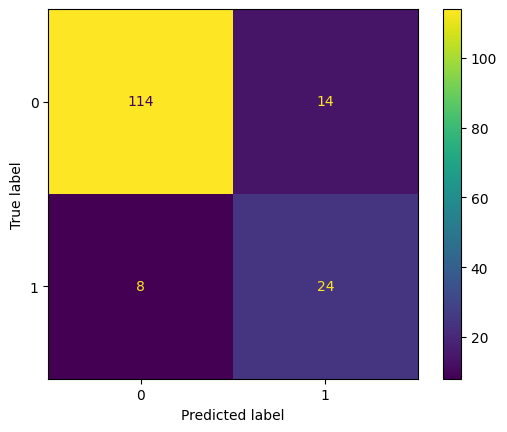

In [41]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(catboost_tuned, X_val, Y_val)

Reduced the threshold for better value to the FN decrase 

In [42]:
import numpy as np
from sklearn.metrics import confusion_matrix, accuracy_score

y_probs = catboost_tuned.predict_proba(X_val)[:,1]
thresholds = np.arange(0.2, 0.55, 0.05)

for t in thresholds:
    y_pred_t = (y_probs >= t).astype(int)
    acc = accuracy_score(Y_val, y_pred_t)
    cm = confusion_matrix(Y_val, y_pred_t)
    fn = cm[1][0]  # False Negative
    fp = cm[0][1]  # False Positive
    
    print(f"Threshold={t:.2f} | Accuracy={acc:.4f} | FN={fn} | FP={fp}")


Threshold=0.20 | Accuracy=0.7875 | FN=4 | FP=30
Threshold=0.25 | Accuracy=0.8063 | FN=4 | FP=27
Threshold=0.30 | Accuracy=0.8187 | FN=4 | FP=25
Threshold=0.35 | Accuracy=0.8063 | FN=6 | FP=25
Threshold=0.40 | Accuracy=0.8063 | FN=7 | FP=24
Threshold=0.45 | Accuracy=0.8375 | FN=7 | FP=19
Threshold=0.50 | Accuracy=0.8625 | FN=8 | FP=14


Final Threshold = 0.3
              precision    recall  f1-score   support

           0       0.96      0.80      0.88       128
           1       0.53      0.88      0.66        32

    accuracy                           0.82       160
   macro avg       0.75      0.84      0.77       160
weighted avg       0.88      0.82      0.83       160



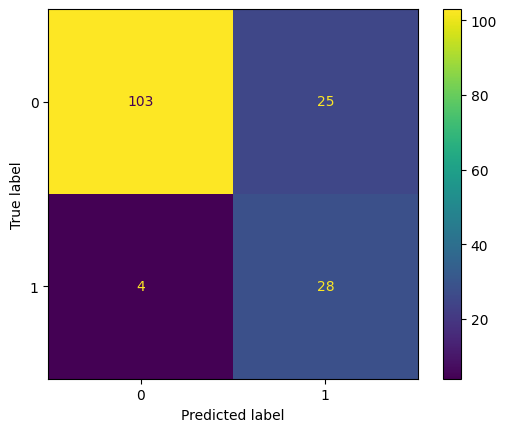

In [43]:
best_threshold = 0.30

y_probs = catboost_tuned.predict_proba(X_val)[:, 1]
y_pred_final = (y_probs >= best_threshold).astype(int)

from sklearn.metrics import classification_report, ConfusionMatrixDisplay

print(f"Final Threshold = {best_threshold}")
print(classification_report(Y_val, y_pred_final))

ConfusionMatrixDisplay.from_predictions(Y_val, y_pred_final)


**The final model is CatBoost with tuned parameters (depth=5, iterations=150, learning_rate=0.05, l2_leaf_reg=7)**
 **and a decision threshold of 0.30, which achieves a healthy balance between overall accuracy (82%) and high sensitivity in detecting true Autism cases (88% Recall)**